# JS09 - Praktikum 1: k-Nearest Neighbors (kNN) pada Dataset Iris
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Praktikum klasifikasi 3 spesies bunga Iris menggunakan algoritma kNN, penskalaan `StandardScaler`, dan pencarian nilai $k$ terbaik.


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
Akurasi: 0.9111111111111111

Confusion Matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



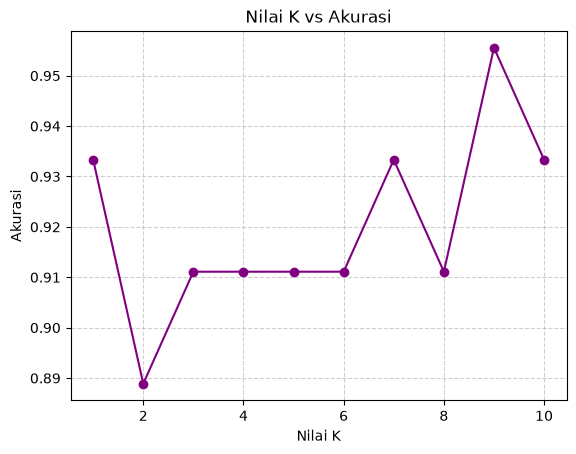

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load data
data = pd.read_csv('iris.csv')
display(data.head())

# 2. Preprocessing
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 3. Model kNN k=3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

print("Akurasi:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 4. Kurva Nilai K vs Akurasi
acc = [KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train).score(X_test_s, y_test) for k in range(1, 11)]
plt.plot(range(1, 11), acc, marker='o', color='purple')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
